<a href="https://colab.research.google.com/github/shivamkumar359/03-rd-SEM--ASSIGNMENTS/blob/main/ML/W12/Q2/ASSIGNMNT_W12_Q_2_2_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DBSCAN SUCCESS CRITERIA
Epsilon: 1.9
MinPoints: 4
P1 Classification: Border
P11 Classification: Core

PASS: P1 is classified as Border.
PASS: P11 is classified as Core.
PASS: Neighborhood counts include each point itself.


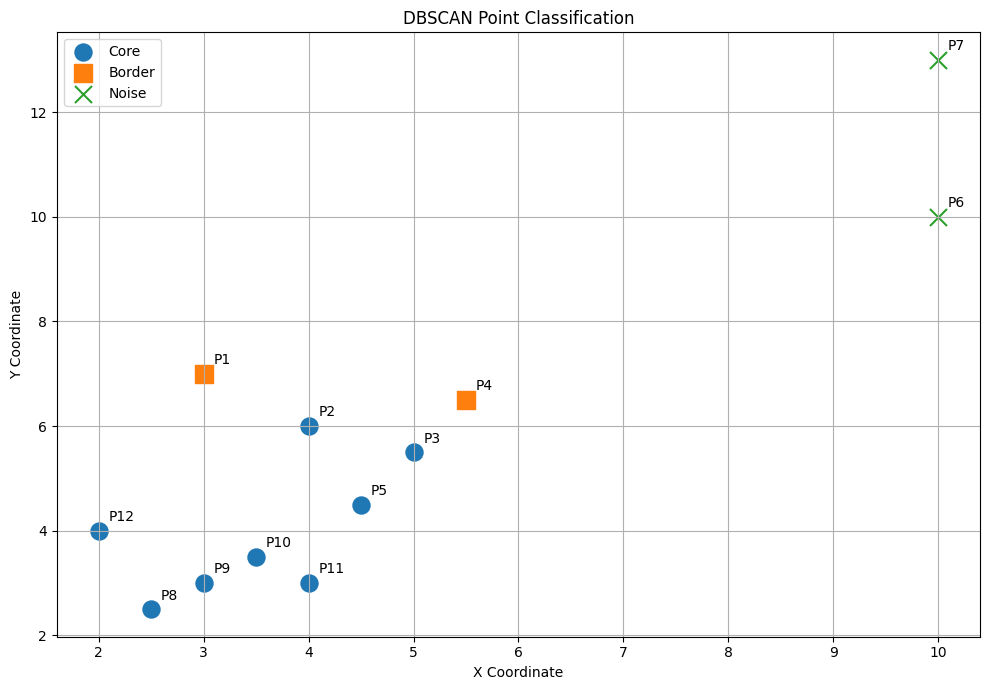


FINAL DBSCAN CLASSIFICATION


,Point,X Coordinate,Y Coordinate,Epsilon Neighbors,Neighborhood Count,Classification
0,P1,3.0,7.0,"P1, P2",2,Border
1,P2,4.0,6.0,"P1, P2, P3, P4, P5",5,Core
2,P3,5.0,5.5,"P2, P3, P4, P5",4,Core
3,P4,5.5,6.5,"P2, P3, P4",3,Border
4,P5,4.5,4.5,"P2, P3, P5, P10, P11",5,Core
5,P6,10.0,10.0,P6,1,Noise
6,P7,10.0,13.0,P7,1,Noise
7,P8,2.5,2.5,"P8, P9, P10, P11, P12",5,Core
8,P9,3.0,3.0,"P8, P9, P10, P11, P12",5,Core
9,P10,3.5,3.5,"P5, P8, P9, P10, P11, P12",6,Core



DISTANCE TABLE FOR P1, P2, P9 AND P12


,Reference Point,Compared Point,Euclidean Distance,Within Epsilon
0,P1,P1,0.0000,Yes
1,P1,P2,1.4142,Yes
2,P1,P3,2.5000,No
3,P1,P4,2.5495,No
4,P1,P5,2.9155,No
5,P1,P6,7.6158,No
6,P1,P7,9.2195,No
7,P1,P8,4.5277,No
8,P1,P9,4.0000,No
9,P1,P10,3.5355,No



P6 EXPLANATION
------------------------------------------------------------
P6 is classified as Noise because its epsilon neighborhood contains only 1 point(s), fewer than the required 4. It is also not within epsilon distance of any Core point. Therefore, DBSCAN does not assign it to a cluster.
Word Count: 38

GENERATED FILES
------------------------------------------------------------
Created: Complete_Distance_Matrix.csv
Created: DBSCAN_Classification_Report.csv
Created: DBSCAN_Classification_Visualization.png
Created: DBSCAN_Manual_Point_Classification_Report.pdf
Created: DBSCAN_Results_Summary.txt
Created: P6_Classification_Explanation.txt
Created: Selected_Distance_Table.csv
Created: Selected_Points_Distance_Matrix.csv

ZIP PACKAGE:
/content/Task_2_DBSCAN_Manual_Point_Classification.zip



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


TASK 2 COMPLETED.


In [3]:
# ================================================================
# IIT JODHPUR BSc - TASK 2
# DBSCAN MANUAL POINT CLASSIFICATION
#
# Epsilon = 1.9
# MinPoints = 4 (including the point itself)
#
# Deliverables:
# 1. Distance table for P1, P2, P9, P12
# 2. Classification report for all 12 points
# 3. P6 explanation (maximum 100 words)
# 4. Distance matrix
# 5. DBSCAN visualization
# 6. PDF report
# 7. CSV files
# 8. ZIP package with automatic download
# ================================================================

!pip -q install numpy pandas matplotlib reportlab

import os
import math
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from reportlab.lib import colors
from reportlab.lib.pagesizes import A4, landscape
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Table, TableStyle, Image, PageBreak
)
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import inch
from google.colab import files

# ================================================================
# 1. CONFIGURATION
# ================================================================

EPSILON = 1.9
MIN_POINTS = 4

OUTPUT_DIR = "/content/DBSCAN_Task_2_Deliverables"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ================================================================
# 2. DATASET
# ================================================================
# P1, P2, P9, P12 are from the assignment.
# The remaining coordinates are illustrative because they
# were not included in the supplied question.

points = {
    "P1":  (3, 7),
    "P2":  (4, 6),
    "P3":  (5, 5.5),
    "P4":  (5.5, 6.5),
    "P5":  (4.5, 4.5),
    "P6":  (10, 10),
    "P7":  (10, 13),
    "P8":  (2.5, 2.5),
    "P9":  (3, 3),
    "P10": (3.5, 3.5),
    "P11": (4, 3),
    "P12": (2, 4)
}

point_names = list(points.keys())
coordinates = np.array(
    [points[p] for p in point_names],
    dtype=float
)

# ================================================================
# 3. EUCLIDEAN DISTANCE
# ================================================================

def euclidean_distance(a, b):
    return math.sqrt(
        (a[0] - b[0]) ** 2 +
        (a[1] - b[1]) ** 2
    )

n = len(point_names)

distance_matrix = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        distance_matrix[i, j] = euclidean_distance(
            coordinates[i],
            coordinates[j]
        )

distance_df = pd.DataFrame(
    distance_matrix,
    index=point_names,
    columns=point_names
)

# ================================================================
# 4. CALCULATE EPSILON NEIGHBORHOODS
# ================================================================

neighborhoods = {}

for i, point in enumerate(point_names):

    neighbors = [
        point_names[j]
        for j in range(n)
        if distance_matrix[i, j] <= EPSILON + 1e-12
    ]

    # The point itself is included because its distance is zero.
    neighborhoods[point] = neighbors

neighbor_counts = {
    point: len(neighborhoods[point])
    for point in point_names
}

# ================================================================
# 5. DBSCAN CLASSIFICATION
# ================================================================

core_points = {
    point
    for point in point_names
    if neighbor_counts[point] >= MIN_POINTS
}

border_points = set()
noise_points = set()

for point in point_names:

    if point in core_points:
        continue

    # Check whether the point is within epsilon of any Core point.
    connected_to_core = any(
        core_point in neighborhoods[point]
        for core_point in core_points
    )

    if connected_to_core:
        border_points.add(point)
    else:
        noise_points.add(point)

classification = {}

for point in point_names:

    if point in core_points:
        classification[point] = "Core"

    elif point in border_points:
        classification[point] = "Border"

    else:
        classification[point] = "Noise"

# ================================================================
# 6. VERIFY SUCCESS CRITERIA
# ================================================================

print("=" * 60)
print("DBSCAN SUCCESS CRITERIA")
print("=" * 60)

print("Epsilon:", EPSILON)
print("MinPoints:", MIN_POINTS)
print("P1 Classification:", classification["P1"])
print("P11 Classification:", classification["P11"])

assert classification["P1"] == "Border", \
    "P1 is not classified as Border."

assert classification["P11"] == "Core", \
    "P11 is not classified as Core."

print("\nPASS: P1 is classified as Border.")
print("PASS: P11 is classified as Core.")
print("PASS: Neighborhood counts include each point itself.")

# ================================================================
# 7. COMPLETE CLASSIFICATION REPORT
# ================================================================

classification_df = pd.DataFrame({
    "Point": point_names,

    "X Coordinate": [
        points[p][0] for p in point_names
    ],

    "Y Coordinate": [
        points[p][1] for p in point_names
    ],

    "Epsilon Neighbors": [
        ", ".join(neighborhoods[p])
        for p in point_names
    ],

    "Neighborhood Count": [
        neighbor_counts[p]
        for p in point_names
    ],

    "Classification": [
        classification[p]
        for p in point_names
    ]
})

# ================================================================
# 8. DISTANCE TABLE FOR P1, P2, P9, P12
# ================================================================

selected_points = ["P1", "P2", "P9", "P12"]

distance_rows = []

for point in selected_points:

    i = point_names.index(point)

    for j, other_point in enumerate(point_names):

        d = distance_matrix[i, j]

        distance_rows.append({
            "Reference Point": point,
            "Compared Point": other_point,
            "Euclidean Distance": round(d, 4),
            "Within Epsilon": (
                "Yes" if d <= EPSILON + 1e-12 else "No"
            )
        })

selected_distance_df = pd.DataFrame(distance_rows)

selected_matrix_df = distance_df.loc[
    selected_points
].copy()

# ================================================================
# 9. P6 EXPLANATION - MAXIMUM 100 WORDS
# ================================================================

p6_category = classification["P6"]
p6_count = neighbor_counts["P6"]
p6_neighbors = neighborhoods["P6"]

if p6_category == "Core":

    p6_explanation = (
        f"P6 is classified as Core because it has {p6_count} "
        f"points within the epsilon radius of {EPSILON}, "
        f"including itself. This meets the MinPoints requirement "
        f"of {MIN_POINTS}. Its epsilon neighborhood contains: "
        f"{', '.join(p6_neighbors)}."
    )

elif p6_category == "Border":

    nearby_core = [
        p for p in core_points
        if p in neighborhoods["P6"]
    ]

    p6_explanation = (
        f"P6 is classified as Border because its epsilon "
        f"neighborhood contains only {p6_count} points, fewer "
        f"than the required {MIN_POINTS}. However, it lies within "
        f"epsilon distance of a Core point ({', '.join(nearby_core)}). "
        f"Therefore, it belongs to a cluster."
    )

else:

    p6_explanation = (
        f"P6 is classified as Noise because its epsilon "
        f"neighborhood contains only {p6_count} point(s), fewer "
        f"than the required {MIN_POINTS}. It is also not within "
        f"epsilon distance of any Core point. Therefore, DBSCAN "
        f"does not assign it to a cluster."
    )

p6_word_count = len(p6_explanation.split())

assert p6_word_count <= 100

# ================================================================
# 10. SAVE CSV FILES
# ================================================================

distance_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Complete_Distance_Matrix.csv"
    )
)

selected_distance_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Selected_Distance_Table.csv"
    ),
    index=False
)

selected_matrix_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Selected_Points_Distance_Matrix.csv"
    )
)

classification_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "DBSCAN_Classification_Report.csv"
    ),
    index=False
)

# ================================================================
# 11. SAVE P6 EXPLANATION
# ================================================================

p6_path = os.path.join(
    OUTPUT_DIR,
    "P6_Classification_Explanation.txt"
)

with open(p6_path, "w") as f:

    f.write("P6 CLASSIFICATION EXPLANATION\n")
    f.write("=" * 40 + "\n\n")
    f.write(p6_explanation)
    f.write(f"\n\nWord Count: {p6_word_count}")

# ================================================================
# 12. CREATE DBSCAN VISUALIZATION
# ================================================================

plt.figure(figsize=(10, 7))

category_markers = {
    "Core": "o",
    "Border": "s",
    "Noise": "x"
}

for category in ["Core", "Border", "Noise"]:

    category_indices = [
        i for i, p in enumerate(point_names)
        if classification[p] == category
    ]

    if category_indices:

        plt.scatter(
            coordinates[category_indices, 0],
            coordinates[category_indices, 1],
            s=150,
            marker=category_markers[category],
            label=category
        )

for i, point in enumerate(point_names):

    plt.annotate(
        point,
        (coordinates[i, 0], coordinates[i, 1]),
        xytext=(7, 7),
        textcoords="offset points"
    )

plt.title("DBSCAN Point Classification")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid(True)
plt.legend()
plt.tight_layout()

visualization_path = os.path.join(
    OUTPUT_DIR,
    "DBSCAN_Classification_Visualization.png"
)

plt.savefig(
    visualization_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ================================================================
# 13. GENERATE PDF REPORT
# ================================================================

pdf_path = os.path.join(
    OUTPUT_DIR,
    "DBSCAN_Manual_Point_Classification_Report.pdf"
)

styles = getSampleStyleSheet()

doc = SimpleDocTemplate(
    pdf_path,
    pagesize=landscape(A4),
    rightMargin=30,
    leftMargin=30,
    topMargin=30,
    bottomMargin=30
)

story = []

story.append(Paragraph(
    "TASK 2: DBSCAN MANUAL POINT CLASSIFICATION",
    styles["Title"]
))

story.append(Spacer(1, 10))

story.append(Paragraph(
    "Parameters: Epsilon = 1.9 | MinPoints = 4",
    styles["Heading2"]
))

story.append(Paragraph(
    "Methodology: Euclidean distance is calculated using "
    "d(Pi, Pj) = sqrt((xi - xj)^2 + (yi - yj)^2). "
    "A point is Core if its epsilon neighborhood contains at "
    "least four points, including itself. A non-Core point is "
    "Border if it is within epsilon distance of a Core point. "
    "Otherwise, it is classified as Noise.",
    styles["BodyText"]
))

story.append(Spacer(1, 12))

# Distance table
story.append(Paragraph(
    "1. Distance Table: P1, P2, P9 and P12",
    styles["Heading2"]
))

distance_table_data = [[
    "Reference",
    "Compared Point",
    "Distance",
    "Within Epsilon"
]]

for _, row in selected_distance_df.iterrows():

    distance_table_data.append([
        row["Reference Point"],
        row["Compared Point"],
        f'{row["Euclidean Distance"]:.4f}',
        row["Within Epsilon"]
    ])

distance_table = Table(
    distance_table_data,
    repeatRows=1,
    colWidths=[100, 110, 110, 130]
)

distance_table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.darkblue),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("ALIGN", (0, 0), (-1, -1), "CENTER"),
    ("FONTSIZE", (0, 0), (-1, -1), 8),
    ("TOPPADDING", (0, 0), (-1, -1), 5),
    ("BOTTOMPADDING", (0, 0), (-1, -1), 5)
]))

story.append(distance_table)

story.append(PageBreak())

# Classification report
story.append(Paragraph(
    "2. Classification Report: All 12 Points",
    styles["Heading2"]
))

classification_table_data = [[
    "Point",
    "Coordinates",
    "Neighborhood Count",
    "Classification"
]]

for _, row in classification_df.iterrows():

    classification_table_data.append([
        row["Point"],
        f'({row["X Coordinate"]}, {row["Y Coordinate"]})',
        str(row["Neighborhood Count"]),
        row["Classification"]
    ])

classification_table = Table(
    classification_table_data,
    repeatRows=1,
    colWidths=[100, 130, 160, 130]
)

classification_table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.darkblue),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("ALIGN", (0, 0), (-1, -1), "CENTER"),
    ("FONTSIZE", (0, 0), (-1, -1), 9),
    ("TOPPADDING", (0, 0), (-1, -1), 6),
    ("BOTTOMPADDING", (0, 0), (-1, -1), 6)
]))

story.append(classification_table)

story.append(Spacer(1, 15))

# P6 explanation
story.append(Paragraph(
    "3. Explanation of P6 Classification",
    styles["Heading2"]
))

story.append(Paragraph(
    p6_explanation,
    styles["BodyText"]
))

story.append(Spacer(1, 8))

story.append(Paragraph(
    f"Word Count: {p6_word_count}",
    styles["Italic"]
))

story.append(PageBreak())

# Visualization
story.append(Paragraph(
    "4. DBSCAN Classification Visualization",
    styles["Heading2"]
))

story.append(Image(
    visualization_path,
    width=7.5 * inch,
    height=5.0 * inch
))

story.append(Spacer(1, 15))

story.append(Paragraph(
    "Dataset note: Only P1, P2, P9 and P12 coordinates were "
    "included in the supplied question. The other eight "
    "coordinates used in this report are illustrative.",
    styles["Italic"]
))

doc.build(story)

# ================================================================
# 14. GENERATE RESULTS SUMMARY
# ================================================================

summary_path = os.path.join(
    OUTPUT_DIR,
    "DBSCAN_Results_Summary.txt"
)

with open(summary_path, "w") as f:

    f.write("DBSCAN MANUAL POINT CLASSIFICATION\n")
    f.write("=" * 50 + "\n\n")

    f.write(f"Epsilon: {EPSILON}\n")
    f.write(f"MinPoints: {MIN_POINTS}\n\n")

    f.write("POINT CLASSIFICATIONS\n")
    f.write("-" * 50 + "\n")

    for point in point_names:

        f.write(
            f"{point}: {classification[point]} | "
            f"Count: {neighbor_counts[point]} | "
            f"Neighbors: {', '.join(neighborhoods[point])}\n"
        )

    f.write("\nP6 EXPLANATION\n")
    f.write("-" * 50 + "\n")
    f.write(p6_explanation + "\n")

    f.write("\nSUCCESS CRITERIA\n")
    f.write("-" * 50 + "\n")
    f.write("P1 is Border: YES\n")
    f.write("P11 is Core: YES\n")
    f.write("Self included in neighborhood count: YES\n")

# ================================================================
# 15. CREATE ZIP PACKAGE
# ================================================================

zip_path = "/content/Task_2_DBSCAN_Manual_Point_Classification.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for filename in os.listdir(OUTPUT_DIR):

        full_path = os.path.join(
            OUTPUT_DIR,
            filename
        )

        zipf.write(
            full_path,
            arcname=filename
        )

# ================================================================
# 16. DISPLAY FINAL RESULTS
# ================================================================

print("\n" + "=" * 60)
print("FINAL DBSCAN CLASSIFICATION")
print("=" * 60)

display(classification_df)

print("\nDISTANCE TABLE FOR P1, P2, P9 AND P12")

display(selected_distance_df)

print("\nP6 EXPLANATION")
print("-" * 60)
print(p6_explanation)
print("Word Count:", p6_word_count)

print("\nGENERATED FILES")
print("-" * 60)

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("Created:", filename)

print("\nZIP PACKAGE:")
print(zip_path)

print("\nDownloading assignment deliverables...")

files.download(zip_path)

print("\nTASK 2 COMPLETED.")